<a href="https://colab.research.google.com/github/studiousdoston/AI-Foundation/blob/main/randomforest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Get the data

In [1]:
import seaborn as sns
import pandas as pd

df = sns.load_dataset("penguins")

In [3]:
df.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


In [4]:
df.shape

(344, 7)

In [5]:
df.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [6]:
df.species.value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


## 2. Clean the data

In [7]:
df = df.dropna(subset=['bill_length_mm']).copy()

df['sex'] = df['sex'].fillna(df['sex'].mode()[0])

df.isna().sum()

,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


### Turn categories into numbers

---

- island: Biscoe → 0, Dream → 1, Torgersen → 2
- sex:    Female → 0, Male → 1

In [8]:
for col in ['island', 'sex']:
  df[col] = df[col].astype('category').cat.codes

df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,2,39.1,18.7,181.0,3750.0,1
1,Adelie,2,39.5,17.4,186.0,3800.0,0
2,Adelie,2,40.3,18.0,195.0,3250.0,0
4,Adelie,2,36.7,19.3,193.0,3450.0,0
5,Adelie,2,39.3,20.6,190.0,3650.0,1


### split into inputs/answers and train/validation

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='species') # Inputs -> independent variables
y = df['species'] # Answer -> dependend variables

X_trn, X_val, y_trn, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)


X_trn.shape, X_val.shape

((256, 6), (86, 6))

## 3. Build one small decision tree and draw it

In [11]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=2, random_state=42)

tree.fit(X_trn, y_trn)

tree.score(X_val, y_val)

0.9883720930232558

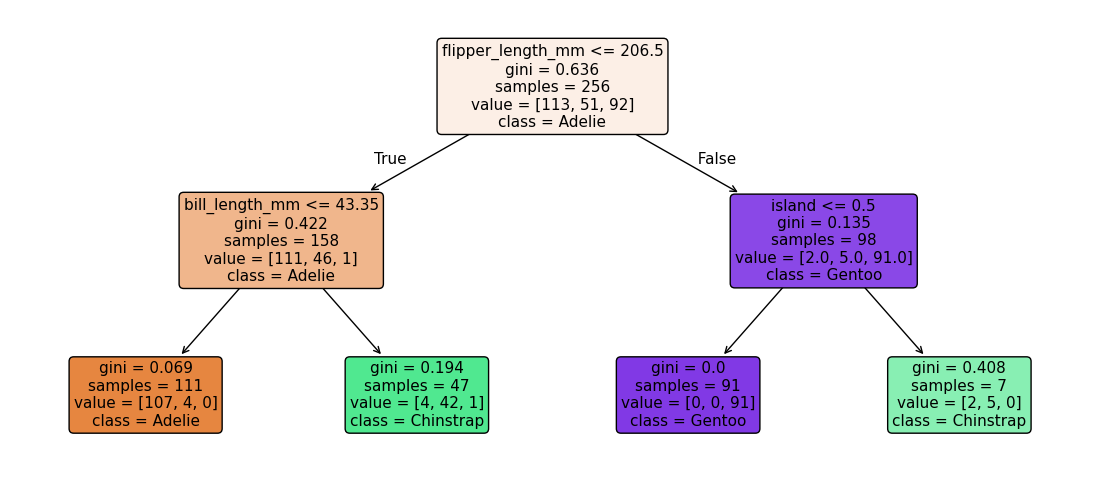

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 6))
plot_tree(tree,
          feature_names= X.columns,
          class_names=tree.classes_,
          filled=True,
          rounded=True,
          fontsize=11)
plt.show()

## 4. Make a tree overfit on purpose

In [13]:
train_acc, val_acc = [], []
depths = range(1, 11)

for d in depths:
  t = DecisionTreeClassifier(max_depth=d, random_state=42)
  t.fit(X_trn, y_trn)
  train_acc.append(t.score(X_trn, y_trn))
  val_acc.append(t.score(X_val, y_val))

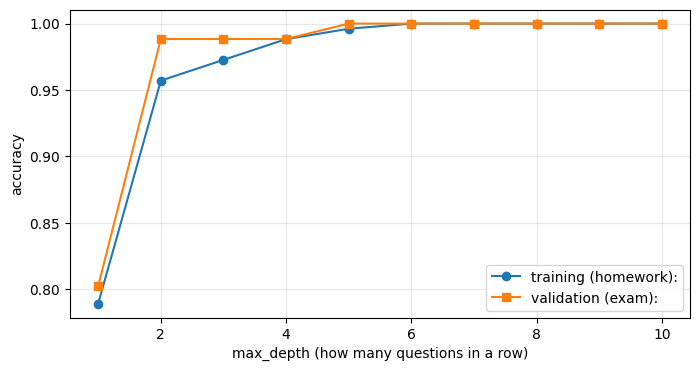

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(depths, train_acc, 'o-', label='training (homework):')
plt.plot(depths, val_acc, 's-', label='validation (exam):')
plt.xlabel('max_depth (how many questions in a row)')
plt.ylabel('accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()



In [15]:
deep = DecisionTreeClassifier(random_state=42).fit(X_trn, y_trn)

deep.get_depth(), deep.get_n_leaves()

deep.score(X_trn, y_trn), deep.score(X_val, y_val)

(1.0, 1.0)

In [16]:
cols = ['body_mass_g', 'bill_depth_mm']
Xh_trn, Xh_val = X_trn[cols], X_val[cols]


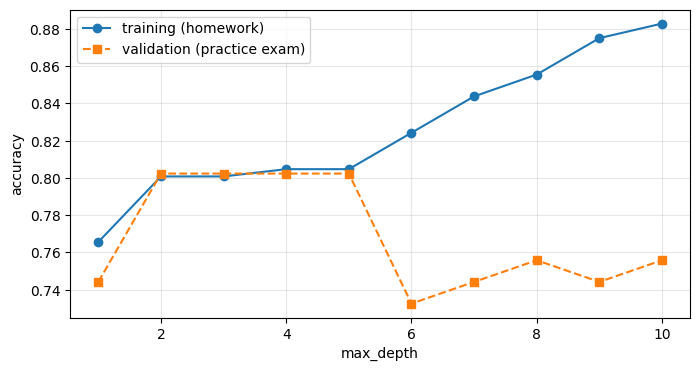

In [17]:
trn_acc, val_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xh_trn, y_trn)
    trn_acc.append(t.score(Xh_trn, y_trn))
    val_acc.append(t.score(Xh_val, y_val))

plt.figure(figsize=(8, 4))
plt.plot(depths, trn_acc, 'o-', label='training (homework)')
plt.plot(depths, val_acc, 's--', label='validation (practice exam)')
plt.xlabel('max_depth'); plt.ylabel('accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 5. Random forest vs single tree

In [18]:
from sklearn.ensemble import RandomForestClassifier

one_tree = DecisionTreeClassifier(random_state=42).fit(Xh_trn, y_trn)

forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(Xh_trn, y_trn)

print('one tree:', one_tree.score(Xh_trn, y_trn), one_tree.score(Xh_val, y_val))
print('forest:  ', forest.score(Xh_trn, y_trn), forest.score(Xh_val, y_val))

one tree: 0.99609375 0.6976744186046512
forest:   0.99609375 0.7558139534883721


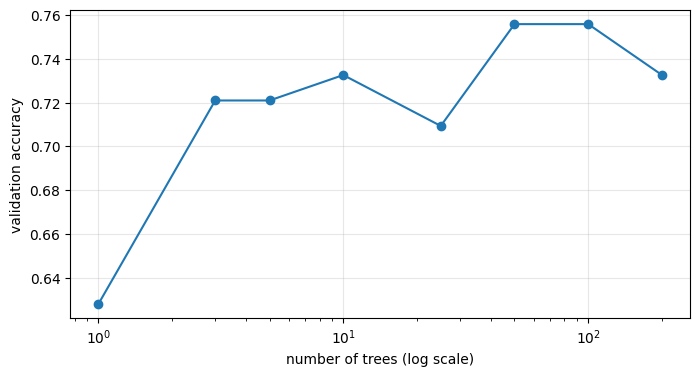

In [19]:
## Does adding more trees help?

sizes = [1, 3, 5, 10, 25, 50, 100, 200]
val_scores = []
for n in sizes:
  rf = RandomForestClassifier(n_estimators=n, random_state=42).fit(Xh_trn, y_trn)
  val_scores.append(rf.score(Xh_val, y_val))
# Build forests with 1, 3, 5 … 200 trees and record validation accuracy


plt.figure(figsize=(8, 4))
plt.plot(sizes, val_scores, 'o-')
plt.xscale('log')
plt.xlabel('number of trees (log scale)'); plt.ylabel('validation accuracy')
plt.grid(alpha=0.3); plt.show()

In [20]:
forest5 = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                 random_state=42).fit(Xh_trn, y_trn)
# min_samples_leaf=5 → every leaf needs ≥ 5 penguins → no memorising single penguins

forest5.score(Xh_trn, y_trn), forest5.score(Xh_val, y_val)
# Training should DROP a bit (less memorising), validation should go UP


(0.8359375, 0.7790697674418605)

## 6. Feature importance on ALL 6 columns 📊

In [21]:
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                            random_state=42).fit(X_trn, y_trn)

rf.score(X_val, y_val)
# Validation accuracy with full information (compare with 0.78 from 2 columns)

1.0

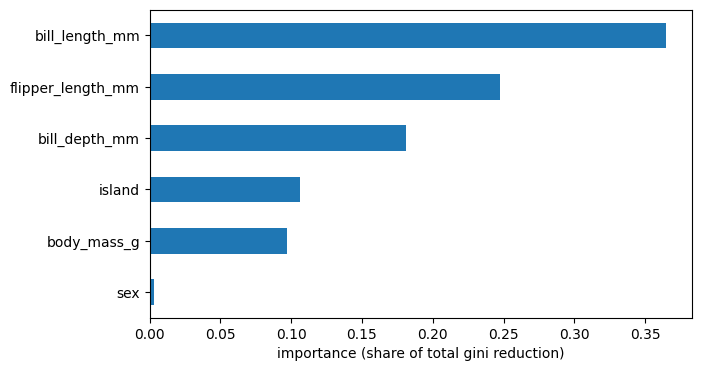

In [22]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

imp.plot.barh(figsize=(7, 4))
plt.xlabel('importance (share of total gini reduction)')
plt.show()
# Horizontal bar chart: the longest bar = the most useful measurement

## 7. Predict my own made-up penguin


In [30]:
new = pd.DataFrame([
    {'island': 0, 'bill_length_mm': 48, 'bill_depth_mm': 15,
     'flipper_length_mm': 220, 'body_mass_g': 5200, 'sex': 1},
    {'island': 2, 'bill_length_mm': 30, 'bill_depth_mm': 18.5,
     'flipper_length_mm': 150, 'body_mass_g': 5000, 'sex': 1},
])[X.columns]

rf.predict(new)


pd.DataFrame(rf.predict_proba(new), columns=rf.classes_).round(2)




,Adelie,Chinstrap,Gentoo
0,0.00,0.00,1.00
1,0.92,0.02,0.06
